<a href="https://colab.research.google.com/github/krishkumarwork3-beep/ucs420/blob/2nd/Copy_of_UCS420_LA9_Starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [ ]:
ROLL_NO = 1024170184         # <-- your full roll number
NAME = "Krish Kumar"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [ ]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [ ]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [ ]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170184   Name: Krish Kumar   Fingerprint: 9FDD3B7E   Tickets: 16

Ticket_ID                                                                          Ticket_Text
      T01 I am unable to use the projector after the latest update. I don't know what changed.
      T02                                                          My roll no. is 1023-03-021.
      T03     I couldn't connect to the Matlab when I use mobile hotspot. It worked yesterday.
      T04                                            The printer won't print; it isn't jammed.
      T05                                                        The LMS says 'Not Submitted'.
      T06                          Email is running slowly since yesterday. Please resolve it.
      T07                             The password keeps asking for login. Can you check this?
      T08                                  The MATLAB has stopped syncing. Can you check this?
      T09                         Server keeps disconnecting o

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [ ]:
rows = []
for tid, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    r = process_ticket(text)
    rows.append({
        "Ticket_ID": tid,
        "Sentences": len(r["sentences"]),
        "Tokens": len(r["tokens"]),
        "Punctuation": len(r["punct"]),
        "Stopwords": len(r["stops"]),
        "Unique_Tokens": len(set(r["tokens"])),
        "Final_Tokens": len(r["final"]),
    })

q1 = pd.DataFrame(rows)

# TOTAL row: sum of each column
total = q1.drop(columns="Ticket_ID").sum()
q1 = pd.concat([q1, pd.DataFrame([{"Ticket_ID": "TOTAL", **total.to_dict()}])],
               ignore_index=True)

print(q1.to_string(index=False))

# Show details for one selected ticket
sel = "T03"   # change to any ticket ID
text = df.loc[df["Ticket_ID"] == sel, "Ticket_Text"].iloc[0]
r = process_ticket(text)
print(f"Ticket {sel}: {text}\n")
print("Tokens      :", r["tokens"])
print("Punctuation :", r["punct"])
print("Stopwords   :", r["stops"])
print("Final tokens:", r["final"])

Ticket_ID  Sentences  Tokens  Punctuation  Stopwords  Unique_Tokens  Final_Tokens
      T01          2      19            2          9             16             8
      T02          2       7            2          3              6             2
      T03          2      17            2          6             15             9
      T04          1      11            2          3             10             6
      T05          1       7            2          1              7             4
      T06          2      11            2          2             10             7
      T07          2      12            2          5             12             5
      T08          2      11            2          5             11             4
      T09          2      12            2          5             12             5
      T10          2      15            2          5             15             8
      T11          2      10            2          3              8             5
      T12       

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*The final tokens that are not real words are fragments created by word_tokenize, which splits contractions into two pieces. For example, “couldn’t” becomes could + n't, and “can’t” becomes ca + n't; “won’t” becomes wo + n't, and “Dr. Rao’s” gives 's. The pipeline only removes tokens made entirely of punctuation and tokens in the NLTK stopword list. n't contains a letter, so is_punct doesn’t remove it, and it isn’t in the stopword list, so it survives into the final tokens. could also survives because it isn’t in the list either. In T03, n't is the clear example.


---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [ ]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re

# ---------- patterns ----------
LONG_WORDS = r"\b[A-Za-z]{6,}\b"                     # words longer than 5 letters
NUMBERS    = r"\d+(?:[.,]\d+)*"                      # 95.5, 2.0.1, 1,250, 5.30 stay whole
CAPITAL    = r"\b[A-Z][A-Za-z]*\b"                   # capitalized words (incl. MATLAB, LMS)
VOWEL      = r"\b[aeiouAEIOU][A-Za-z]*\b"            # words starting with a vowel

EMAIL = r"\b[\w.+-]+@[\w-]+(?:\.[\w-]+)+\b"
URL   = r"(?:https?://|www\.)[\w\-./~%?=&#]*[\w/]"   # stops before a trailing '.'
PHONE = (r"(?<!\d)(?:\+91[\s-]?)?\d{5}[\s-]?\d{5}(?!\d)"   # +91 98765 43210 / +91-98765-43210
         r"|(?<!\d)0\d{2,4}-\d{3}-\d{4}(?!\d)")             # 0175-239-3201

def extract(text):
    return {
        "long_words": re.findall(LONG_WORDS, text),
        "numbers":    re.findall(NUMBERS, text),
        "capitalized": re.findall(CAPITAL, text),
        "vowel_words": re.findall(VOWEL, text),
    }

def mask(text):
    # order matters: emails first so the URL pattern can't eat part of them
    text = re.sub(EMAIL, "<EMAIL>", text)
    text = re.sub(URL, "<URL>", text)
    text = re.sub(PHONE, "<PHONE>", text)
    return text

# ---------- 1) TEST_LINES ----------
print("=== TEST_LINES ===")
for line in TEST_LINES:
    print("\nLINE   :", line)
    for k, v in extract(line).items():
        print(f"{k:12}:", v)
    print("MASKED :", mask(line))

# ---------- 2) Raw tickets ----------
print("\n=== RAW TICKETS ===")
for tid, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    print(f"\n{tid}: {text}")
    for k, v in extract(text).items():
        print(f"  {k:12}:", v)
    print("  masked      :", mask(text))

# ---------- Observe: capitalized only because they start a sentence ----------
all_caps, sent_start = 0, 0
for text in df["Ticket_Text"]:
    all_caps   += len(re.findall(CAPITAL, text))
    sent_start += len(re.findall(r"(?:^|(?<=[.!?])\s+)([A-Z][A-Za-z]*)", text))
print(f"\nCapitalized words: {all_caps}, of which sentence-initial: {sent_start}")

=== TEST_LINES ===

LINE   : Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
long_words  : ['helpdesk', 'thapar', 'thapar', 'thapar']
numbers     : []
capitalized : ['Mail']
vowel_words : ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']
MASKED : Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>.

LINE   : Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
long_words  : ['Version']
numbers     : ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1,250']
capitalized : ['Call', 'Version', 'Rs']
vowel_words : ['or', 'is']
MASKED : Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

LINE   : The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
long_words  : []
numbers     : ['5.30']
capitalized : ['The']
vowel_words : ['of', 'art', 'isn', 'open', 'in', 'at']
MASKED : The state-of-the-

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*Of the 39 capitalized words, 28 are capitalized only because they begin a sentence (e.g. The, It, Can, Please). The remaining 11 are capitalized for other reasons: the pronoun “I”, acronyms and product names such as LMS, VPN, MATLAB, Windows, and quoted text like ‘Not Submitted’. This shows that capitalization is a weak signal for proper nouns, since most capitalized words here are just sentence starters.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [ ]:
import re
from nltk.tokenize import RegexpTokenizer, word_tokenize

# One pattern, alternatives tried in order (most specific first).
# Non-capturing groups only, so RegexpTokenizer returns whole matches.
PATTERN = r"""(?x)
    (?:[\w.+-]+@[\w-]+(?:\.[\w-]+)+)                       # email
  | (?:(?:https?://|www\.)[\w\-./~%?=&#]*[\w/])            # URL
  | (?:(?<!\d)(?:\+91[\s-]?)?\d{5}[\s-]?\d{5}(?!\d))       # phone: +91 98765 43210 / +91-98765-43210
  | (?:(?<!\d)0\d{2,4}-\d{3}-\d{4}(?!\d))                  # phone: 0175-239-3201
  | (?:\d+(?:[.,]\d+)+)                                    # decimals, versions, 1,250 (95.5, 2.0.1)
  | (?:[A-Za-z]+(?:['\-][A-Za-z]+)+)                       # contractions + hyphenated (isn't, Wi-Fi, state-of-the-art)
  | (?:\w+)                                                # plain words / integers
  | (?:[^\w\s])                                            # any other single punctuation char
"""

_tok = RegexpTokenizer(PATTERN)

def my_tokenize(text):
    return _tok.tokenize(text)

# ---------- 1) TEST_LINES ----------
print("=== TEST_LINES ===")
for line in TEST_LINES:
    print("\nLINE        :", line)
    print("my_tokenize :", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))

# ---------- 2) Tickets ----------
print("\n=== TICKETS ===")
diff_ids = []
for tid, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    mine, nltk_t = my_tokenize(text), word_tokenize(text)
    if mine != nltk_t:
        diff_ids.append(tid)
        print(f"\n{tid}: {text}")
        print("  my_tokenize  :", mine)
        print("  word_tokenize:", nltk_t)
        print("  only in mine :", [t for t in mine if t not in nltk_t])
        print("  only in nltk :", [t for t in nltk_t if t not in mine])

print(f"\nTickets tokenized differently: {len(diff_ids)} of {len(df)}")
print("IDs:", diff_ids)

=== TEST_LINES ===

LINE        : Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize : ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

LINE        : Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize : ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

LINE        : The state-of-the-art lab isn't open

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*6 of the 16 tickets are tokenized differently by my_tokenize and word_tokenize. The differences come from four causes:

Contractions (T01, T03, T04): word_tokenize splits them into two tokens (couldn't becomes could + n't, won't becomes wo + n't, isn't becomes is + n't), while my pattern keeps them whole.
Abbreviations (T14): word_tokenize keeps p.m. as one token, while mine splits it into p, ., m, ..
Hyphenated identifiers (T02): word_tokenize keeps the roll number 1023-03-021 whole, while mine splits it into 1023, -, 03, -, 021.
Quotes (T05): word_tokenize attaches the opening quote to the next word ('Not), while mine separates the quote mark (', Not).

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [ ]:
import nltk
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

# ---------- unique final tokens across all tickets ----------
final_tokens = []
for text in df["Ticket_Text"]:
    final_tokens.extend(process_ticket(text)["final"])
unique_final = sorted(set(final_tokens))
print("Unique final tokens:", len(unique_final))
print(unique_final)

# ---------- stemmers / lemmatizer ----------
porter    = PorterStemmer()
lancaster = LancasterStemmer()
# Suffix rule: pick after inspecting your own words (see print above).
# min=4 stops short words like "is", "bus" from being chopped.
regexp    = RegexpStemmer(r"(ing|ed|es|s|ly)$", min=4)
lemm      = WordNetLemmatizer()

def to_wn_pos(tag):
    if tag.startswith("J"): return wordnet.ADJ
    if tag.startswith("V"): return wordnet.VERB
    if tag.startswith("R"): return wordnet.ADV
    return wordnet.NOUN

# POS-tag each word (tagging single words loses context, but works for a unique-word list)
tagged = nltk.pos_tag(unique_final)

rows = []
for word, tag in tagged:
    rows.append({
        "Word": word,
        "POS": tag,
        "Porter": porter.stem(word),
        "Lancaster": lancaster.stem(word),
        "Regexp": regexp.stem(word),
        "Lemma": lemm.lemmatize(word, to_wn_pos(tag)),
    })

q4 = pd.DataFrame(rows)

# keep only words where the four outputs are not all identical
differ = q4[q4[["Porter", "Lancaster", "Regexp", "Lemma"]].nunique(axis=1) > 1]
print(f"\nWords where outputs differ: {len(differ)} of {len(q4)}\n")
print(differ.to_string(index=False))

Unique final tokens: 63
["'not", '1023-03-021', '11', '5.30', 'asking', 'assignment', 'changed', 'check', 'connect', 'could', 'crashes', 'deadline', 'disconnecting', 'email', 'error', 'getting', 'help', 'hotspot', 'jammed', 'keep', 'keeps', 'know', 'laptop', 'latest', 'lms', 'logged', 'login', 'matlab', 'mobile', "n't", 'need', 'opening', 'p.m.', 'password', 'please', 'print', 'printer', 'projector', 'resolve', 'roll', 'running', 'says', 'server', 'several', 'showing', 'since', 'slowly', 'stopped', 'submitted', 'syncing', 'times', 'today', 'tried', 'unable', 'update', 'use', 'vpn', 'wifi', 'windows', 'wo', 'worked', 'working', 'yesterday']

Words where outputs differ: 32 of 63

      Word POS    Porter Lancaster     Regexp      Lemma
assignment  NN    assign    assign assignment assignment
   changed VBD     chang     chang      chang     change
  deadline  JJ   deadlin   deadlin   deadline   deadline
     error  NN     error        er      error      error
   getting VBG       get    

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*Over-stemming: Lancaster reduces projector to project, and unable to un, which cuts too much and changes or destroys the meaning. Under-stemming: the Regexp stemmer reduces running to runn and getting to gett. It removes -ing but leaves the doubled consonant, so these stems do not match run and get.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

          Corpus  Tokens  Unique    TTR
 S1 (all tokens)     191      95 0.4974
   S2 (no punct)     160      90 0.5625
      S3 (final)      93      63 0.6774
S4 (S3 + Porter)      93      61 0.6559

Top 10 words in S1:
  '.'          24
  'the'        12
  'i'          8
  'yesterday'  7
  'it'         6
  'is'         5
  "n't"        4
  'matlab'     4
  'worked'     4
  'can'        4

Top 10 words in S3:
  'yesterday'  7
  "n't"        4
  'matlab'     4
  'worked'     4
  'check'      4
  'use'        3
  'mobile'     2
  'hotspot'    2
  'lms'        2
  'since'      2


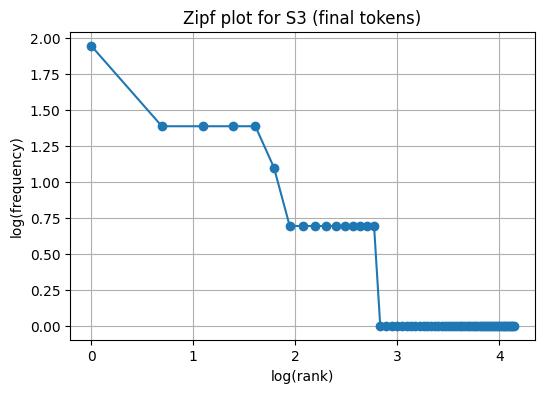


Top 5 bigrams in S1:
  ('yesterday', '.')  7
  ('.', 'i')  5
  ('the', 'matlab')  4
  ('.', 'it')  4
  ('it', 'worked')  4

Top 5 bigrams in S3:
  ('worked', 'yesterday')  4
  ('use', 'mobile')  2
  ('mobile', 'hotspot')  2
  ('hotspot', 'worked')  2
  ('since', 'yesterday')  2


In [ ]:
import math
from collections import Counter
import matplotlib.pyplot as plt
from nltk.util import bigrams
from nltk.stem import PorterStemmer

porter = PorterStemmer()

# ---------- build the four corpora (all tickets concatenated) ----------
S1, S2, S3 = [], [], []
for text in df["Ticket_Text"]:
    r = process_ticket(text)
    S1.extend(r["tokens"])                              # all lowercase tokens
    S2.extend(t for t in r["tokens"] if t not in r["punct"])   # no punctuation
    S3.extend(r["final"])                               # no punctuation, no stopwords
S4 = [porter.stem(t) for t in S3]                       # S3 after Porter

# S2: safer to filter with is_punct directly (avoids list-membership quirks)
S2 = [t for t in S1 if not is_punct(t)]

corpora = {"S1 (all tokens)": S1, "S2 (no punct)": S2,
           "S3 (final)": S3, "S4 (S3 + Porter)": S4}

# ---------- tokens, unique tokens, TTR ----------
rows = []
for name, toks in corpora.items():
    n, v = len(toks), len(set(toks))
    rows.append({"Corpus": name, "Tokens": n, "Unique": v, "TTR": round(v / n, 4)})
stats = pd.DataFrame(rows)
print(stats.to_string(index=False))

# ---------- top 10 words of S1 and S3 ----------
print("\nTop 10 words in S1:")
for w, c in Counter(S1).most_common(10):
    print(f"  {w!r:12} {c}")

print("\nTop 10 words in S3:")
for w, c in Counter(S3).most_common(10):
    print(f"  {w!r:12} {c}")

# ---------- Zipf plot for S3: log(rank) vs log(frequency) ----------
freqs = sorted(Counter(S3).values(), reverse=True)
ranks = range(1, len(freqs) + 1)
plt.figure(figsize=(6, 4))
plt.plot([math.log(r) for r in ranks], [math.log(f) for f in freqs], "o-")
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Zipf plot for S3 (final tokens)")
plt.grid(True)
plt.show()

# ---------- top 5 bigrams of S1 and S3 ----------
print("\nTop 5 bigrams in S1:")
for bg, c in Counter(bigrams(S1)).most_common(5):
    print(f"  {bg}  {c}")

print("\nTop 5 bigrams in S3:")
for bg, c in Counter(bigrams(S3)).most_common(5):
    print(f"  {bg}  {c}")

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR rises from 0.4974 in S1 to 0.5625 in S2 because removing punctuation drops 31 tokens (mostly the repeated ., which appears 24 times) but only 5 unique types. It rises again to 0.6774 in S3 because removing stopwords (the, i, it, is, to) takes out 67 tokens that repeat heavily, while only 27 types disappear. TTR then falls slightly to 0.6559 in S4 because Porter stemming does not change the token count (93) but merges inflected forms into the same stem, reducing unique types from 63 to 61 (e.g. keep and keeps become keep, time and times become time). So TTR goes up when frequent, low-information tokens are removed, and goes down when variants are collapsed


Question 6

(a) TTR rises from 0.4974 in S1 to 0.5625 in S2 because removing punctuation drops 31 tokens (mostly the repeated ., which appears 24 times) but only 5 unique types. It rises again to 0.6774 in S3 because removing stopwords (the, i, it, is, to) takes out 67 tokens that repeat heavily, while only 27 types disappear. TTR then falls slightly to 0.6559 in S4 because Porter stemming does not change the token count (93) but merges inflected forms into the same stem, reducing unique types from 63 to 61 (e.g. keep and keeps become keep, time and times become time). So TTR goes up when frequent, low-information tokens are removed, and goes down when variants are collapsed

(b) Example where the tokenizers differ:

For “I couldn’t connect to the Matlab...” (T03), word_tokenize gives could + n't, while my_tokenize keeps couldn't whole. My pattern treats letters joined by an apostrophe as one word, while NLTK follows Penn Treebank rules and splits the negation clitic. Another is the email it.helpdesk@thapar.edu, which mine keeps as one token while NLTK splits it into it.helpdesk, @, thapar.edu.

(c) Undesirable stemming:

Lancaster stems unable to un, which loses nearly all meaning, and projector to project, which turns a device into a verb or a task. Porter produces non-words such as resolv (from resolve) and deadlin.

(d) POS-aware lemmatization:

tried (VBD) is lemmatized to try, but Porter and Lancaster give tri, which is not a word. Likewise changed becomes change, while stemmers give chang. The lemmatizer uses the POS tag to apply the correct rule and returns a real dictionary word, so the meaning is preserved.